# **K-Nearest Neighbors Regression for the Insurance Premium Prediction**

Group 4: Ahmed, Jana, Abdulrahman, Leen

## **Introduction**


Health insurance companies need to estimate how much a customer is likely to cost in order to set fair premiums. In this project, we use the Medical Cost Personal Dataset (1,338 customers) to predict each customer's annual medical expenses from six features: age, sex, BMI, number of children, smoking status, and region.

Our assigned algorithm is **K-Nearest Neighbors (KNN) Regression**. We explain how it works, explore the data, prepare it for modeling, train and tune a KNN model, evaluate it with MAE, MSE, RMSE and R², and finally compare it with other regression models.

## **Algorithm Explanation**





### 1. What is the algorithm?

K-Nearest Neighbors (KNN) Regression is a supervised machine learning algorithm that predicts a continuous value, such as insurance charges, from the values of the most similar examples in the training data. It is a non-parametric, instance-based (lazy) learner: it learns no equation or parameters and simply stores the training data, using it directly at prediction time.

**Example:**
We want to predict the insurance charges for a new customer:

Age 30, BMI 28, smoker = No

With K = 3, KNN searches the training data for the 3 most similar customers, for example:

| Neighbor | Age | BMI | Smoker | Charges |
|---|---|---|---|---|
| 1 | 31 | 27.5 | No | 4,200 |
| 2 | 29 | 28.4 | No | 3,900 |
| 3 | 30 | 29.0 | No | 4,500 |

The predicted charges are the average of their charges:

(4,200 + 3,900 + 4,500) / 3 = **4,200**

So the model predicts that this customer will have charges of about **$4,200**.

### 2. How does the algorithm work?
- Save the data. The model keeps all the training examples and their answers (charges).

- Measure closeness. When a new person comes in, the model checks how close they are to every person in the data, by comparing their age, BMI, smoking status, and so on.

- Pick the closest K. It chooses the K people who are most similar to the new person.

- Take the average. The prediction is the average of those K people’s charges. Optionally, closer people can count more than farther ones.




**Choosing K:**

- K too small (e.g. 1): the model relies on just one or two people, so a single unusual case can mess up the prediction. (Overfitting)
- K too large: the model averages over too many people, including ones who aren’t really similar, so the prediction becomes too general. (Underfitting)


We try different values of K and pick the one that gives the best results.

### 3. When should this algorithm be used?
- The dataset is small to medium-sized, since predictions get slow on large data.

- There are few features, and they are relevant.

- The relationship between features and target is non-linear or complex.

- Similar inputs are expected to have similar outputs. For example, people of similar age, BMI, and smoking status tend to have similar insurance charges.

- You care more about prediction than about an interpretable equation.

### 4. Advantages and Limitations

**Advantages**
- Simple and easy to understand
- No training step: the model just stores the data
- Captures non-linear relationships
- Makes no assumptions about the shape of the relationship (e.g. linearity)
- Few settings to tune (mainly K)

**Limitations**
- Needs feature scaling, since features with large values dominate the distance
- Slow predictions on large datasets
- Works poorly with many or irrelevant features
- Cannot predict values outside the range seen in training
- Hard to interpret: no coefficients or feature weights
- Sensitive to noise when K is small

## **Importing Libraries**

In [ ]:
# Data Handling
import os
import pandas as pd
import numpy as np
import kagglehub

# Data Preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

# Regression Models
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR

# Model Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

## **Dataset Loading and Initial Inspection**

In [ ]:
# Download the dataset from Kaggle
path = kagglehub.dataset_download("noordeen/insurance-premium-prediction")

# Display the files available in the downloaded folder
print("Files in folder:", os.listdir(path))

# Define the expected CSV file path
file_path = os.path.join(path, "insurance.csv")

# Load the dataset into a pandas DataFrame
df = pd.read_csv(file_path)

# Display the first five rows
df.head()

Using Colab cache for faster access to the 'insurance-premium-prediction' dataset.
Files in folder: ['insurance.csv']


,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86


In [ ]:
# Display descriptive statistics for numerical columns
df.describe()

,age,bmi,children,expenses
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.665471,1.094918,13270.422414
std,14.049960,6.098382,1.205493,12110.011240
min,18.000000,16.000000,0.000000,1121.870000
25%,27.000000,26.300000,0.000000,4740.287500
50%,39.000000,30.400000,1.000000,9382.030000
75%,51.000000,34.700000,2.000000,16639.915000
max,64.000000,53.100000,5.000000,63770.430000


In [ ]:
# Display column names, data types, and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   expenses  1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display the column names
print("Columns:", df.columns.tolist())

Dataset shape: (1338, 7)
Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'expenses']


In [ ]:
# Display the frequency of each category
categorical_cols = ["sex", "smoker", "region"]

for col in categorical_cols:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts())


Value counts for sex:
sex
male      676
female    662
Name: count, dtype: int64

Value counts for smoker:
smoker
no     1064
yes     274
Name: count, dtype: int64

Value counts for region:
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


## **Data Quality**

In [ ]:
# Check the number of missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Count duplicate rows
duplicates_count = df.duplicated().sum()
print("\nNumber of duplicate rows:", duplicates_count)

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
expenses    0
dtype: int64

Number of duplicate rows: 1


In [ ]:
# Remove duplicate rows and reset the index
df = df.drop_duplicates().reset_index(drop=True)

# Confirm the updated dataset dimensions
print("Dataset shape after removing duplicates:", df.shape)

# Verify that no duplicate rows remain
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after removing duplicates: (1337, 7)
Remaining duplicates: 0


### Features and target  selection

**Features: 'age', 'sex', 'bmi', 'children', 'smoker', 'region'**

**Target: expenses**

## **Exploratory Data Analysis (EDA)**

### The histogram below shows us how each column is distributed

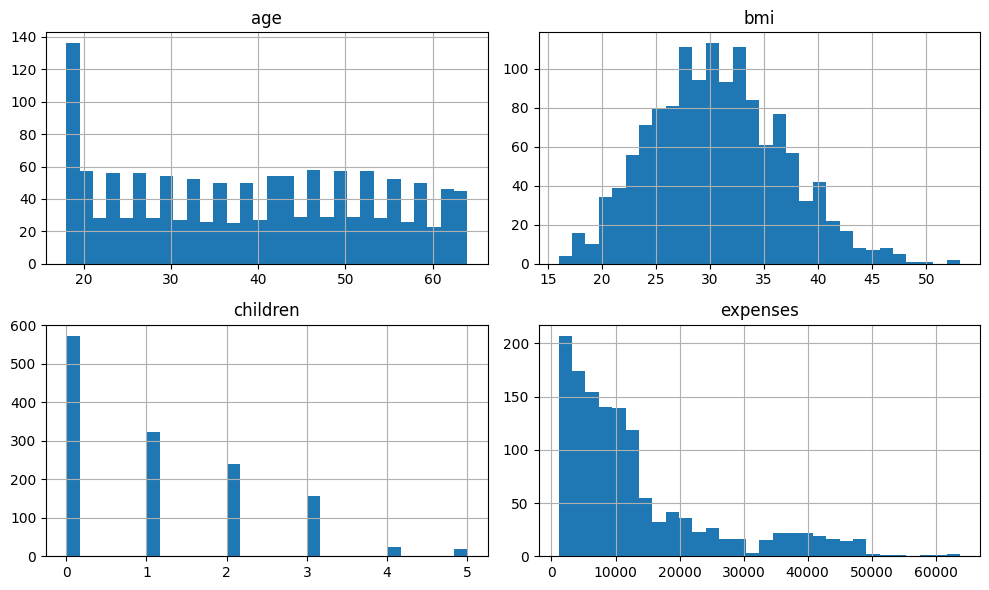

In [ ]:
# Plot a histogram for each numerical column to see how the values are distributed
df.hist(figsize=(10, 6), bins=30)

# Adjust spacing so the charts don't overlap
plt.tight_layout()

# Display the charts
plt.show()

**Findings:**
- **Expenses** are strongly right-skewed: most customers pay under \$15,000, a small group pays much more (up to \$63,000). These extreme values will be harder for KNN to predict, because few similar neighbors exist.
- **Age** is spread fairly evenly between 18 and 64, with a spike at 18–19.
- **BMI** is roughly normally distributed around 30.
- **Children**: most customers have 0–2 children

### Which of our features has a relationship?
- We will use a correlation heatmap to show that

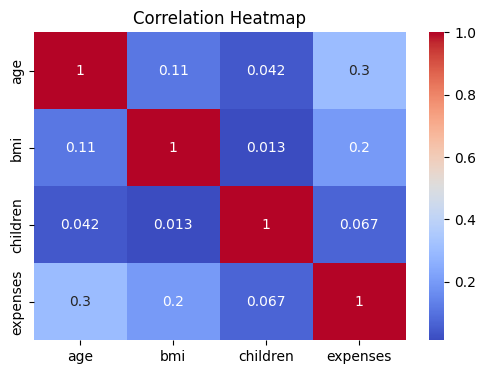

In [ ]:
# Create a figure for the heatmap
plt.figure(figsize=(6, 4))

# Show the correlation between the numerical columns, with the values written on each cell
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")

# Add a title and display the chart
plt.title("Correlation Heatmap")
plt.show()

**Findings:**
- **Age** has the strongest correlation with expenses among the numeric features, followed by **BMI**. **Children** is very weak.
- All correlations are weak (0.3 or less), so no single numeric feature explains expenses well.
- **Important:** `smoker`, `sex` and `region` are text columns, so they don't appear here. Correlation also only measures *linear* relationships. To look deeper, we use scatter plots colored by smoking status.

### Does age affect expenses, and does smoking change this relationship?
- The heatmap showed a small correlation between age and expenses. A scatter plot colored by smoking status shows the relationship in more detail.

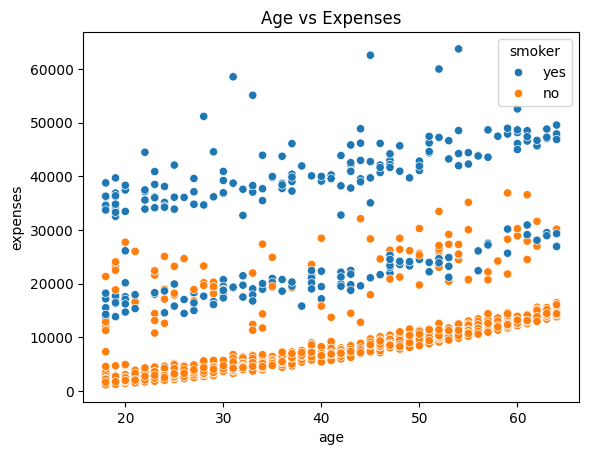

In [ ]:
# Plot age against expenses, coloring each point by smoking status
sns.scatterplot(data=df, x="age", y="expenses", hue="smoker")

# Add a title and display the chart
plt.title("Age vs Expenses")
plt.show()

**Findings:**
- Expenses rise with age for everyone.
- The points form three bands: non-smokers at the bottom, smokers at the top, and a mix in the middle.
- Smoking affects expenses more than age.

### Does BMI affect expenses on its own, or only together with smoking?
- BMI had a weak correlation with expenses. Coloring by smoker shows whether that weak correlation hides a stronger pattern.

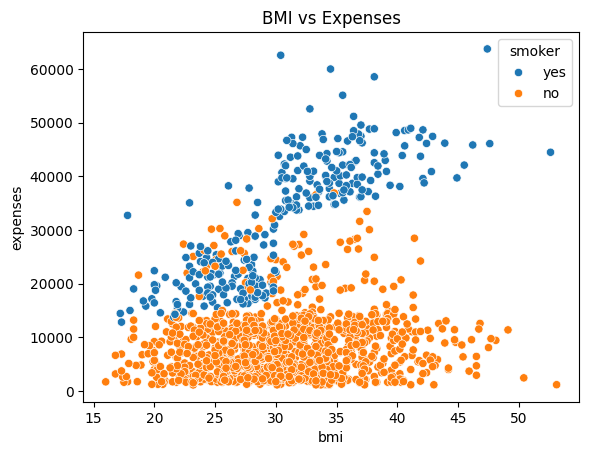

In [ ]:
# Plot BMI against expenses, coloring each point by smoking status
sns.scatterplot(data=df, x="bmi", y="expenses", hue="smoker")

# Add a title and display the chart
plt.title("BMI vs Expenses")
plt.show()

**Findings:**
- For non-smokers, BMI barely affects expenses.
- For smokers, expenses jump sharply above BMI 30.
- BMI matters mainly when combined with smoking.

### How big is the difference in expenses between smokers and non-smokers?

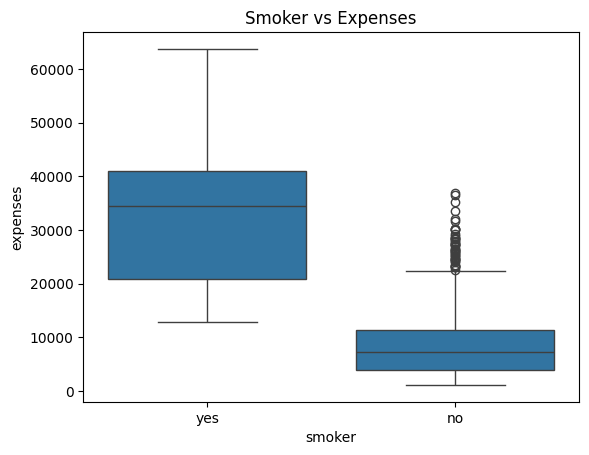

In [ ]:
# Compare the distribution of expenses for smokers and non-smokers
sns.boxplot(data=df, x="smoker", y="expenses")

# Add a title and display the chart
plt.title("Smoker vs Expenses")
plt.show()

**Findings:**
- Smokers pay far more than non-smokers: the median expense for smokers is several times higher, and almost all high-cost customers are smokers.
- This makes `smoker` the strongest predictor of expenses in the dataset.

### Do sex, region and number of children affect expenses?

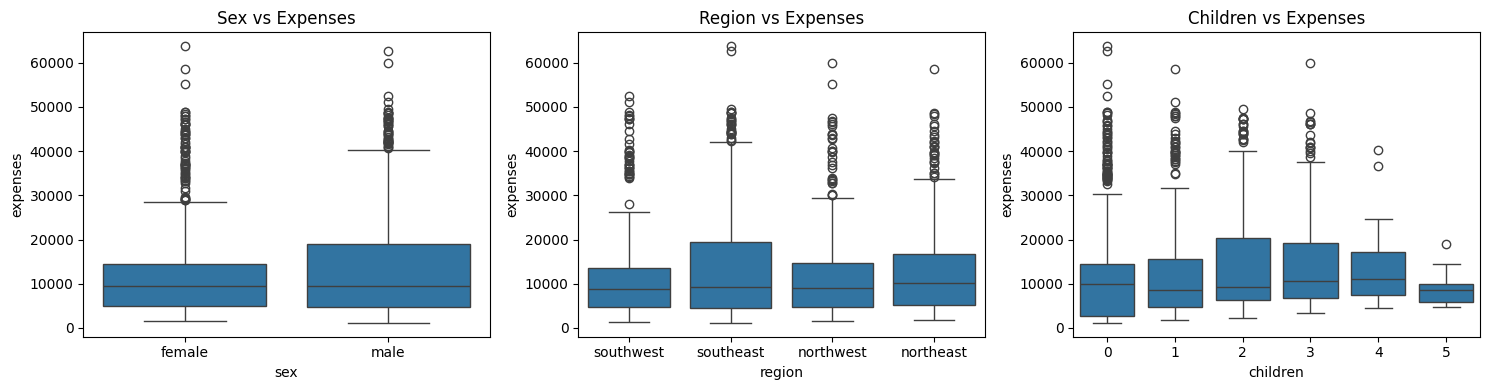

In [ ]:
# Create 3 charts next to each other
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Compare expenses across sex, region, and number of children
sns.boxplot(data=df, x="sex", y="expenses", ax=axes[0])
sns.boxplot(data=df, x="region", y="expenses", ax=axes[1])
sns.boxplot(data=df, x="children", y="expenses", ax=axes[2])

# Add a title to each chart
axes[0].set_title("Sex vs Expenses")
axes[1].set_title("Region vs Expenses")
axes[2].set_title("Children vs Expenses")

# Adjust spacing and display the charts
plt.tight_layout()
plt.show()

**Findings:**
- The boxes are very similar across sex, regions and number of children, so these features have **little effect** on expenses.
- This matters for KNN: it treats every feature as equally important when measuring distance. Weak features can add noise and pull in the wrong neighbors. We test this in the section "Can removing weak features improve KNN?".

## **Data Preprocessing**

In [ ]:
# Encoding categorical features into numerical values
df = pd.get_dummies(df,columns=categorical_cols,drop_first=True,dtype=int)

# Display the first five rows after encoding
df.head()

,age,bmi,children,expenses,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.9,0,16884.92,0,1,0,0,1
1,18,33.8,1,1725.55,1,0,0,1,0
2,28,33.0,3,4449.46,1,0,0,1,0
3,33,22.7,0,21984.47,1,0,1,0,0
4,32,28.9,0,3866.86,1,0,1,0,0


In [ ]:
# Separate input features and target variable
X = df.drop(columns=["expenses"]).copy()
y = df["expenses"].copy()

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Select numerical features that require scaling
numerical_cols = ["age", "bmi", "children"]

# Create copies to preserve the original data
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Convert numerical columns to float to avoid dtype warnings
X_train_scaled[numerical_cols] = (
    X_train_scaled[numerical_cols].astype(float)
)
X_test_scaled[numerical_cols] = (
    X_test_scaled[numerical_cols].astype(float)
)

# Fit the scaler using training data only
scaler = StandardScaler()

X_train_scaled[numerical_cols] = scaler.fit_transform(
    X_train_scaled[numerical_cols]
)

# Apply the same scaling to the test data
X_test_scaled[numerical_cols] = scaler.transform(
    X_test_scaled[numerical_cols]
)

print("Training set:", X_train_scaled.shape)
print("Testing set:", X_test_scaled.shape)

Training set: (1069, 8)
Testing set: (268, 8)


## **Baseline KNN Model**

In [ ]:
# Initialize the baseline KNN model
knn_model = KNeighborsRegressor(n_neighbors=5)

# Train KNN using scaled training features
knn_model.fit(X_train_scaled, y_train)

# Predict expenses for the test set
y_pred = knn_model.predict(X_test_scaled)

In [ ]:

# Calculate regression evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display the evaluation results
print("Baseline KNN Results")
print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))


Baseline KNN Results
MAE: 4494.898
MSE: 65043912.231
RMSE: 8064.981
R2 Score: 0.646


### Why does KNN need feature scaling?
KNN measures distance, so features with large values dominate. To show this, we train the same baseline KNN (K = 5) on unscaled data and compare it with the scaled baseline above.

In [ ]:
# Train the same baseline KNN on the unscaled data
knn_unscaled = KNeighborsRegressor(n_neighbors=5)
knn_unscaled.fit(X_train, y_train)

# Predict on the unscaled test set
y_pred_unscaled = knn_unscaled.predict(X_test)

# Compare R² with and without scaling
print("R² without scaling:", round(r2_score(y_test, y_pred_unscaled), 3))
print("R² with scaling:   ", round(r2_score(y_test, y_pred), 3))

R² without scaling: 0.102
R² with scaling:    0.646


**Findings:**
- Without scaling, R² is only **0.102**. With scaling, it rises to **0.646**.
- Without scaling, age (18–64) and BMI (16–53) dominate the distance, while smoker (0/1) barely counts, even though it's the most important feature.
- Scaling puts all features on a comparable range, so KNN finds truly similar customers. This shows why scaling is essential for KNN.

## **KNN Hyperparameter Tuning**

In [ ]:
# Define the hyperparameters to test
param_grid = {"n_neighbors": list(range(1, 31)), "weights": ["uniform", "distance"],
    "p": [1, 2]   # 1 = Manhattan distance, 2 = Euclidean distance
}

# Initialize GridSearchCV
grid_search = GridSearchCV( estimator=KNeighborsRegressor(), param_grid=param_grid, scoring="neg_root_mean_squared_error", cv=5, n_jobs=-1, return_train_score=True)

# Search for the best hyperparameter combination
grid_search.fit(X_train_scaled, y_train)

# Display the best results
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation RMSE:", round(-grid_search.best_score_, 3))

Best Parameters: {'n_neighbors': 5, 'p': 1, 'weights': 'distance'}
Best Cross-Validation RMSE: 6665.556


In [ ]:
# Retrieve the best KNN model
best_knn = grid_search.best_estimator_

# Predict on the test set
y_pred_tuned = best_knn.predict(X_test_scaled)

# Calculate evaluation metrics
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_mse = mean_squared_error(y_test, y_pred_tuned)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, y_pred_tuned)

# Display tuned KNN results
print("Tuned KNN Results")
print("MAE:", round(tuned_mae, 3))
print("MSE:", round(tuned_mse, 3))
print("RMSE:", round(tuned_rmse, 3))
print("R2 Score:", round(tuned_r2, 3))

Tuned KNN Results
MAE: 3999.364
MSE: 50348934.715
RMSE: 7095.698
R2 Score: 0.726


**Tuning Results:**
- GridSearchCV (optimizing RMSE) selected `n_neighbors = 5`, `weights = distance`, and `p = 1` (Manhattan distance).
- Compared with the baseline KNN, the tuned model improved on every metric:
  - MAE: 4494.898 → **3999.364** (≈ 11.0% lower)
  - RMSE: 8064.981 → **7095.698** (≈ 12.0% lower)
  - R²: 0.646 → **0.726**

### How does K affect overfitting and underfitting?

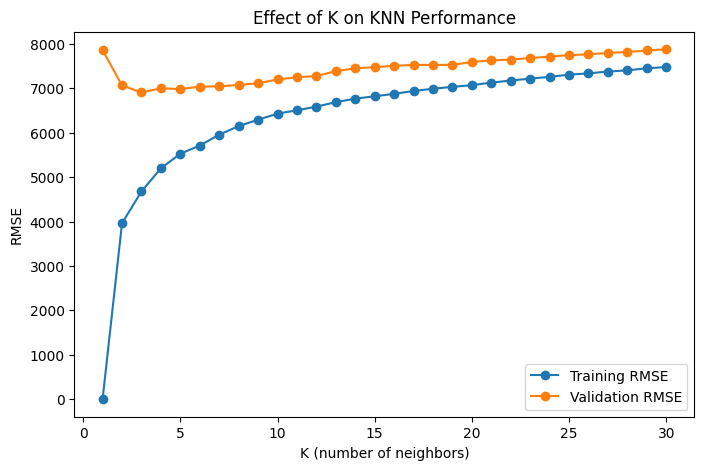

In [ ]:
# Convert the grid search results into a table
results_df = pd.DataFrame(grid_search.cv_results_)

# Keep only the results with uniform weights and the best distance type (p)
# (with distance weights, the training error is always 0, so the curve is not useful)
subset = results_df[
    (results_df["param_weights"] == "uniform") &
    (results_df["param_p"] == grid_search.best_params_["p"])
]

# Plot training and validation RMSE for each value of K
plt.figure(figsize=(8, 5))
plt.plot(subset["param_n_neighbors"], -subset["mean_train_score"], marker="o", label="Training RMSE")
plt.plot(subset["param_n_neighbors"], -subset["mean_test_score"], marker="o", label="Validation RMSE")

# Add labels, title and legend, then display the chart
plt.xlabel("K (number of neighbors)")
plt.ylabel("RMSE")
plt.title("Effect of K on KNN Performance")
plt.legend()
plt.show()

**Findings:**
- **K = 1:** training RMSE is near 0, but validation RMSE is high (~7,850). The model memorizes the training data, so it **overfits**.
- **K ≈ 3–5:** validation RMSE reaches its lowest point (~6,950). This is the best balance.
- **K > 5:** validation RMSE slowly rises again (~7,900 at K = 30). The model averages over customers who aren't similar, so it **underfits**.
- As K grows, the gap between the two lines shrinks, because the model becomes simpler and less sensitive to individual points.

### Can removing weak features improve KNN?
The EDA showed that sex, region and children have little effect on expenses. Since KNN treats all features as equally important, we test KNN using only the strongest features: age, BMI and smoker.

In [ ]:
# Keep only the strongest features found in the EDA
selected_features = ["age", "bmi", "smoker_yes"]

# Select these features from the scaled training and testing data
X_train_selected = X_train_scaled[selected_features]
X_test_selected = X_test_scaled[selected_features]

# Tune KNN again using only the selected features
# (return_train_score=True saves the training scores for the K-effect graph)
grid_selected = GridSearchCV(estimator=KNeighborsRegressor(), param_grid=param_grid,
                             scoring="neg_root_mean_squared_error", cv=5, n_jobs=-1,
                             return_train_score=True)
grid_selected.fit(X_train_selected, y_train)

# Get the best model and predict on the test set
best_knn_selected = grid_selected.best_estimator_
y_pred_selected = best_knn_selected.predict(X_test_selected)

# Display the results
print("Best Parameters:", grid_selected.best_params_)
print("MAE:", round(mean_absolute_error(y_test, y_pred_selected), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_selected)), 3))
print("R2 Score:", round(r2_score(y_test, y_pred_selected), 3))

Best Parameters: {'n_neighbors': 15, 'p': 1, 'weights': 'uniform'}
MAE: 2801.034
RMSE: 4962.277
R2 Score: 0.866


**Findings:**
- Using only age, BMI and smoker improved KNN from R² 0.726 to **0.866**, and both MAE and RMSE dropped by about 30% (MAE 3999 → 2801, RMSE 7096 → 4962).
- This confirms the EDA: sex, region and children add noise to the distance calculation and pull in the wrong neighbors.
- The best K increased from 5 to 15: with less noise, KNN can safely average over more neighbors.
- Feature selection improved KNN more than hyperparameter tuning did, which shows how important it is for distance-based models.

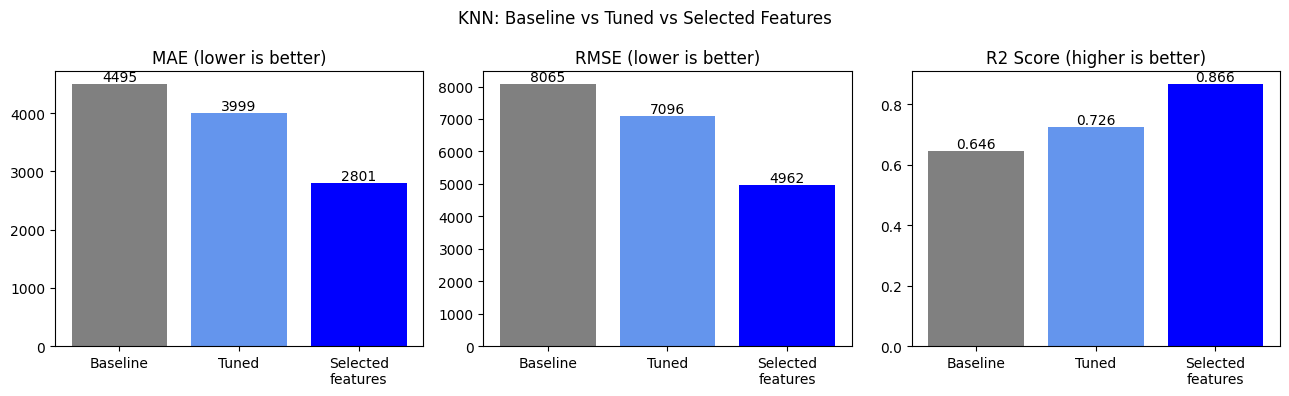

In [ ]:
# Calculate the metrics for all three KNN models
baseline_mae = mean_absolute_error(y_test, y_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
baseline_r2 = r2_score(y_test, y_pred)

selected_mae = mean_absolute_error(y_test, y_pred_selected)
selected_rmse = np.sqrt(mean_squared_error(y_test, y_pred_selected))
selected_r2 = r2_score(y_test, y_pred_selected)

# Names and colors of the three models
model_names = ["Baseline", "Tuned", "Selected\nfeatures"]
colors = ["gray", "cornflowerblue", "blue"]

# Values for each chart
metrics = {
    "MAE (lower is better)": [baseline_mae, tuned_mae, selected_mae],
    "RMSE (lower is better)": [baseline_rmse, tuned_rmse, selected_rmse],
    "R2 Score (higher is better)": [baseline_r2, tuned_r2, selected_r2]
}

# Create 3 charts next to each other
plt.figure(figsize=(13, 4))

for i, (title, values) in enumerate(metrics.items(), start=1):
    plt.subplot(1, 3, i)
    bars = plt.bar(model_names, values, color=colors)
    plt.title(title)

    # Show the value on top of each bar
    if "R2" in title:
        plt.bar_label(bars, fmt="%.3f")
    else:
        plt.bar_label(bars, fmt="%.0f")

plt.suptitle("KNN: Baseline vs Tuned vs Selected Features")
plt.tight_layout()
plt.show()

### How good are our predictions?


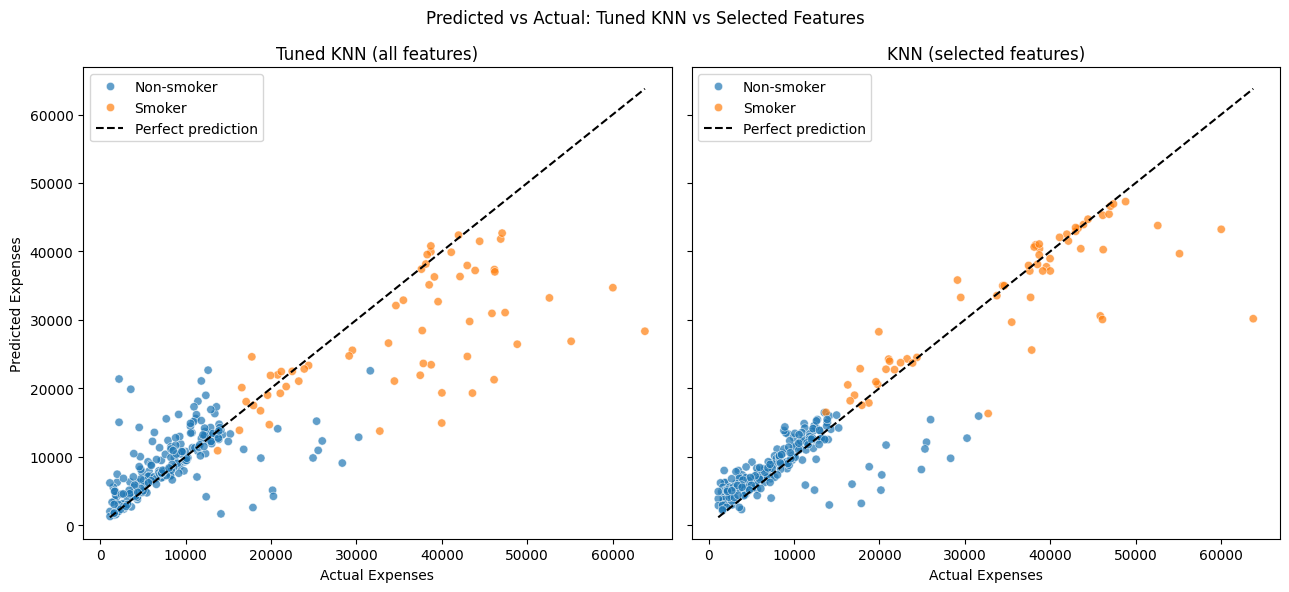

In [ ]:
# Color each customer by smoking status (same customers in both charts)
smoker_label = X_test["smoker_yes"].map({1: "Smoker", 0: "Non-smoker"})

# The two models to compare
charts = [
    ("Tuned KNN (all features)", y_pred_tuned),
    ("KNN (selected features)", y_pred_selected)
]

# Two charts next to each other, with the same axes
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True)

for ax, (title, predictions) in zip(axes, charts):

    # Plot actual vs predicted expenses
    sns.scatterplot(x=y_test, y=predictions, hue=smoker_label, alpha=0.7, ax=ax)

    # Draw the "perfect prediction" line (predicted = actual)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
            "k--", label="Perfect prediction")

    # Add labels, title and legend
    ax.set_xlabel("Actual Expenses")
    ax.set_ylabel("Predicted Expenses")
    ax.set_title(title)
    ax.legend()

plt.suptitle("Predicted vs Actual: Tuned KNN vs Selected Features")
plt.tight_layout()
plt.show()

**Findings:**
- Tuned KNN (all features) underpredicts many high-cost smokers, with points far below the perfect-prediction line.
- With only age, BMI and smoker, the points sit much closer to the line, which is why RMSE dropped from 7,096 to 4,962.
- Some errors remain: a few non-smokers with high costs and the most expensive smokers (above $50,000) are still underpredicted.

## **Model Comparison**

In [ ]:
# Define models and the data each model will use
models = {
    "Baseline KNN": (
        KNeighborsRegressor(n_neighbors=5),
        X_train_scaled,
        X_test_scaled
    ),
    "Tuned KNN": (
        best_knn,
        X_train_scaled,
        X_test_scaled
    ),
    "KNN (Selected Features)": (
        best_knn_selected,
        X_train_selected,
        X_test_selected
    ),
    "Linear Regression": (
        LinearRegression(),
        X_train,
        X_test
    ),
    "Ridge Regression": (
        Ridge(),
        X_train_scaled,
        X_test_scaled
    ),
    "Decision Tree": (
        DecisionTreeRegressor(random_state=42),
        X_train,
        X_test
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=42),
        X_train,
        X_test
    ),
    "SVR": (
        SVR(),
        X_train_scaled,
        X_test_scaled
    )
}

# Store evaluation results
results = []

for name, (model, Xtr, Xte) in models.items():

    # Train the model
    model.fit(Xtr, y_train)

    # Make predictions
    predictions = model.predict(Xte)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Create a comparison table
comparison_df = pd.DataFrame(results)

# Sort by MAE from lowest to highest
comparison_df = comparison_df.sort_values(
    by="MAE"
).reset_index(drop=True)

comparison_df.round(3)

,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest,2641.144,2.204831e+07,4695.562,0.880
1,KNN (Selected Features),2801.034,2.462419e+07,4962.277,0.866
2,Decision Tree,2846.939,3.720997e+07,6099.998,0.798
3,Tuned KNN,3999.364,5.034893e+07,7095.698,0.726
4,Linear Regression,4177.268,3.548147e+07,5956.633,0.807
5,Ridge Regression,4194.115,3.566649e+07,5972.143,0.806
6,Baseline KNN,4494.898,6.504391e+07,8064.981,0.646
7,SVR,9261.829,2.082563e+08,14431.087,-0.133


In [ ]:
# Test whether the other models also improve with only the selected features
other_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

for name, model in other_models.items():

    # Train the model using only age, bmi and smoker
    model.fit(X_train[selected_features], y_train)

    # Predict on the test set
    predictions = model.predict(X_test[selected_features])

    # Display the R2 score
    print(name, "R2 with selected features:", round(r2_score(y_test, predictions), 3))

Linear Regression R2 with selected features: 0.805
Decision Tree R2 with selected features: 0.798
Random Forest R2 with selected features: 0.876


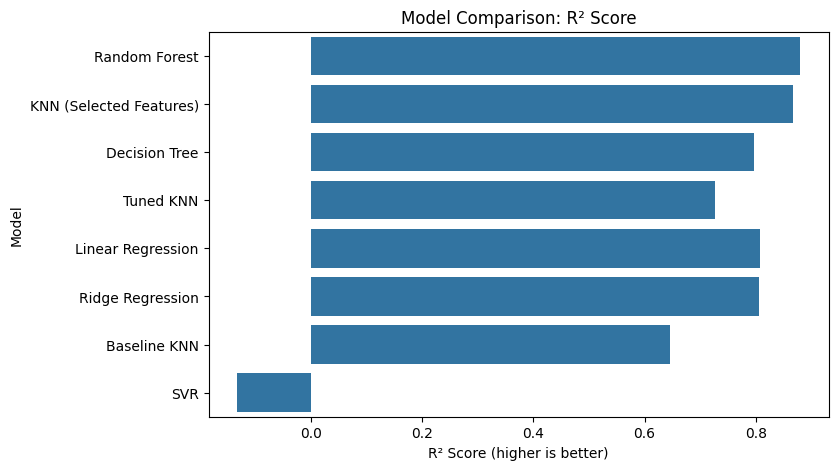

In [ ]:
# Visualize R² for each model
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison_df, x="R2 Score", y="Model")
plt.title("Model Comparison: R² Score")
plt.xlabel("R² Score (higher is better)")
plt.show()

### Comparison Findings

- **Random Forest performed best on every metric** (MAE 2641, RMSE 4696, R² 0.880), because tree-based models capture the sharp jumps in insurance costs (e.g. smokers with high BMI).
- **KNN with selected features ranked second on every metric** (MAE 2801, RMSE 4962, R² 0.866), very close to Random Forest and ahead of Decision Tree and Linear Regression.
- **Tuned KNN with all features** has a lower MAE than Linear Regression (3999 vs 4177) but a higher RMSE (7096 vs 5957). It predicts typical customers well but makes larger errors on high-cost cases.
- **SVR** performed worst (R² -0.133), most likely because its default settings don't suit a target measured in thousands.
- **Feature selection mainly helps KNN:** when we gave Linear Regression, Decision Tree and Random Forest only age, BMI and smoker, their R² stayed about the same (0.805, 0.798, 0.876). This is likely because these models can already give weak features little weight, while KNN treats every feature equally in its distance.

> Only KNN was tuned, so the other models could also improve with tuning.



## **Conclusion**

In this project, we applied KNN Regression to predict medical insurance expenses. After encoding and scaling the data, the baseline KNN (K = 5) achieved an R² of 0.646. Tuning with GridSearchCV improved it to 0.726, and keeping only the strongest features (age, BMI and smoker) raised it to **0.866**, making KNN the second-best model after Random Forest (0.880).

The main lesson is that KNN depends heavily on how distance is measured: scaling the features, choosing a good K, and removing weak features all made a large difference. KNN still under-predicts some high-cost smokers, where similar neighbors are rare, which is why Random Forest remains slightly better on this dataset.